# Advanced Transport Phenomena

## Practical session 1 - 1D advection-diffusion

from Alberto Cuoci and Adrien Guillonneau

The point of this practical is to get a basic idea of Python coding, basic methods to solve PDE (FDM), basic methods for time integration (Implicit and explicit Euler) and get started on the implementation of numerical algorithms.


## 0. Python notes for this practical

Comments start with `#`. Printing uses `print(...)`. NumPy arrays are created with `np.zeros(n)` or `np.linspace(a, b, n)`, and indexed starting at 0. A NumPy array is not copied by plain assignment: `b = a` gives two names for the same array, and `b = a.copy()` is needed for an independent copy. This point becomes relevant in Part 2, where arrays are updated inside a loop.


## 1. The analytical solution


The advection-diffusion equation in 1D, on a domain of length $L$, is considered:

$$
\frac{\partial f}{\partial t} + u \frac{\partial f}{\partial x} = \Gamma \frac{\partial^2 f}{\partial x^2}
$$

with periodic boundary conditions and initial condition $f(t=0,x) = A\sin(2\pi k x)$. This problem has a known exact solution:

$$
a(x,t) = A \exp\left(-4\pi^2 k^2 \Gamma t\right) \sin\left(2\pi k (x - ut)\right)
$$

The sine wave moves to the right at speed $u$, and its amplitude decreases over time because of diffusion. This exact formula is examined directly, before any numerical scheme is introduced.

### 1.2 Time independant wave

The simplest case is considered first, no time dependance and only the initial shape of the wave, $f(x) = A\sin(2\pi k x)$, is examined.

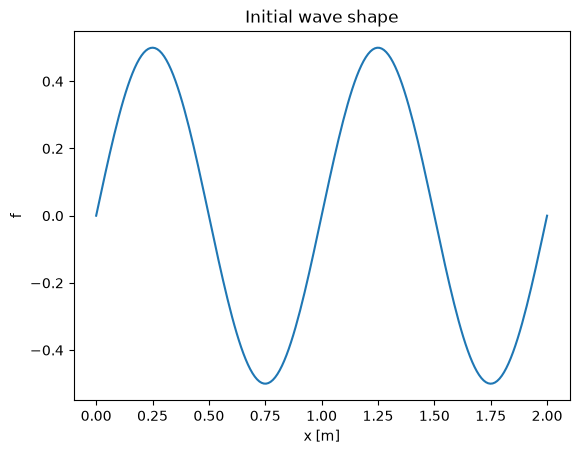

In [1]:
import numpy as np
import matplotlib.pyplot as plt

L = 2.0   # domain length [m]
A = 0.5   # amplitude
k = 1     # wave number [1/m]

x = np.linspace(0, L, 200)
f = A * np.sin(2 * np.pi * k * x)

plt.plot(x, f)
plt.xlabel("x [m]")
plt.ylabel("f")
plt.title("Initial wave shape")
plt.show()

Change `k` to `2` and run the cell again. The wave becomes shorter, since `k` counts how many full waves fit into the domain.

### 1.3 Time dependant wave

Time is now introduced. The wave travels and its height decreases. The analytical solution is implemented as a function, for reuse later:

In [3]:
def analytical_solution(x, t, A, k, D, u):
    '''Exact solution of the 1D advection-diffusion equation.'''
    return A * np.exp(-4 * np.pi**2 * k**2 * D * t) * np.sin(2 * np.pi * k * (x - u * t))

The diffusion coefficient $\Gamma$ (called `D` in the code) and the velocity $u$ are set below, and the wave is plotted at a few different times on the same figure:

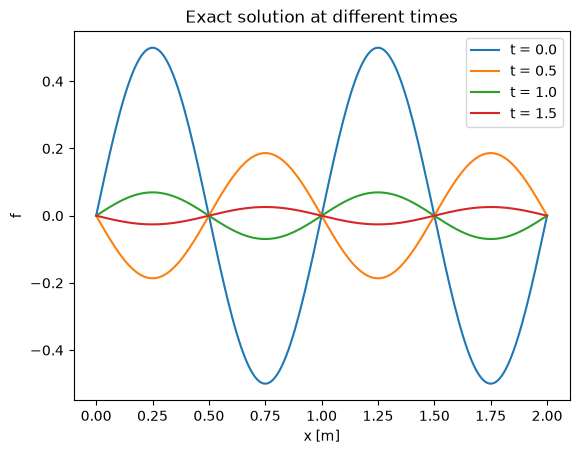

In [4]:
D = 0.05   # diffusion coefficient [m2/s] GAMMA
u = 1.0    # velocity [m/s]

times = [0.0, 0.5, 1.0, 1.5]

for t in times:
    a = analytical_solution(x, t, A, k, D, u)
    plt.plot(x, a, label=f"t = {t}")

plt.xlabel("x [m]")
plt.ylabel("f")
plt.legend()
plt.title("Exact solution at different times")
plt.show()

The wave shifts to the right as $t$ increases, and its peak decreases. Both effects follow directly from the formula: the shift comes from the $x - ut$ term, and the decay comes from the $\exp(-4\pi^2k^2\Gamma t)$ term.

### 1.4 Time animation



In [5]:
import matplotlib.animation as animation
from IPython.display import HTML

t_values = np.linspace(0, 2.0, 80)

fig, ax = plt.subplots(figsize=(7, 5))
line, = ax.plot(x, analytical_solution(x, 0, A, k, D, u))
ax.set_ylim(-0.6, 0.6)
ax.set_xlabel("x [m]")
ax.set_ylabel("f")
title = ax.set_title("")

def update(frame):
    t = t_values[frame]
    line.set_ydata(analytical_solution(x, t, A, k, D, u))
    title.set_text(f"t = {t:.2f} s")
    return line, title

anim = animation.FuncAnimation(fig, update, frames=len(t_values), interval=50, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## 2. The numerical solution

The same problem is now solved numerically, with the explicit (forward) Euler method in time and centered (CDS), 2nd order differences in space, on a grid of `n_points` points. The discretized equation is:

$$
\frac{f_i^{n+1} - f_i^n}{\Delta t} + u\,\frac{f_{i+1}^n - f_{i-1}^n}{2h} = \Gamma\,\frac{f_{i+1}^n - 2f_i^n + f_{i-1}^n}{h^2}
$$

where $h$ is the grid spacing and $n$ is the time level.

### 2.1 Setting up the grid

The same `L`, `A`, `k`, `D`, `u` values from Part 1 are kept, with the grid and time settings added:

In [6]:
L = 2.0   # domain length [m]
A = 0.5   # amplitude
k = 1     # wave number [1/m]
D = 0.05   # diffusion coefficient [m2/s] GAMMA
u = 1.0    # velocity [m/s]

n_points = 21   # number of grid points
nstep = 100     # number of time steps
dt = 0.05       # time step [s]

h = L / (n_points - 1)   # grid step [m]

### 2.2 Building numerical scheme

The solution array is pre-allocated and the initial condition is set, matching Part 1 but with `n_points` grid points instead of the 200 used earlier for plotting:

In [7]:
f = np.zeros(n_points)
for i in range(n_points):
    f[i] = A * np.sin(2 * np.pi * k * h * i)

At every step, the current solution is saved, the interior points are updated, and the periodic boundary condition is applied to obtain exterior points. 

Saving with `.copy()` is required: `f_old = f` would make `f_old` and `f` the same array, and `f_old` would change while it is still being used to update `f`.

In [9]:
def run_numerical_scheme(n_points, nstep, L, dt, u, D, A, k):
    '''Explicit Euler, centered finite differences, periodic boundary conditions.'''
    h = L / (n_points - 1) #grid spacing
    f = np.zeros(n_points)
    for i in range(n_points):
        f[i] = A * np.sin(2 * np.pi * k * h * i)

    f_history = [f.copy()]
    t_history = [0.0]
    t = 0.0

    for m in range(nstep):
        f_old = f.copy()

        for i in range(1, n_points - 1):
            f[i] = (f_old[i] - (u * dt / (2 * h)) * (f_old[i+1] - f_old[i-1]) + D * (dt / h**2) * (f_old[i+1] - 2*f_old[i] + f_old[i-1]))

        f[-1] = (f_old[-1]
                 - (u * dt / (2 * h)) * (f_old[1] - f_old[-2])
                 + D * (dt / h**2) * (f_old[1] - 2*f_old[-1] + f_old[-2]))
        f[0] = f[-1]

        t = t + dt
        f_history.append(f.copy())
        t_history.append(t)

    return {"f_history": f_history, "t_history": t_history, "h": h}

result = run_numerical_scheme(n_points, nstep, L, dt, u, D, A, k)
print(result)

{'f_history': [array([ 0.00000000e+00,  2.93892626e-01,  4.75528258e-01,  4.75528258e-01,
        2.93892626e-01,  6.12323400e-17, -2.93892626e-01, -4.75528258e-01,
       -4.75528258e-01, -2.93892626e-01, -1.22464680e-16,  2.93892626e-01,
        4.75528258e-01,  4.75528258e-01,  2.93892626e-01,  1.83697020e-16,
       -2.93892626e-01, -4.75528258e-01, -4.75528258e-01, -2.93892626e-01,
       -2.44929360e-16]), array([-0.14694631,  0.14694631,  0.38471044,  0.47552826,  0.38471044,
        0.14694631, -0.14694631, -0.38471044, -0.47552826, -0.38471044,
       -0.14694631,  0.14694631,  0.38471044,  0.47552826,  0.38471044,
        0.14694631, -0.14694631, -0.38471044, -0.47552826, -0.38471044,
       -0.14694631]), array([-2.65828378e-01, -9.54097912e-17,  2.65828378e-01,  4.30119350e-01,
        4.30119350e-01,  2.65828378e-01,  5.37764278e-17, -2.65828378e-01,
       -4.30119350e-01, -4.30119350e-01, -2.65828378e-01, -1.23165367e-16,
        2.65828378e-01,  4.30119350e-01,  4.30119

### 2.3 Plotting

Before the scheme is trusted, it is checked against a known reference. At $t=0$, the numerical solution should match the initial sine wave exactly, and at any later time it should be close to the exact solution from Part 1:

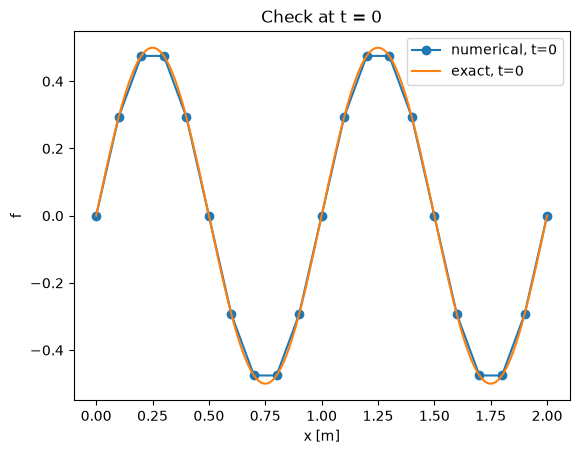

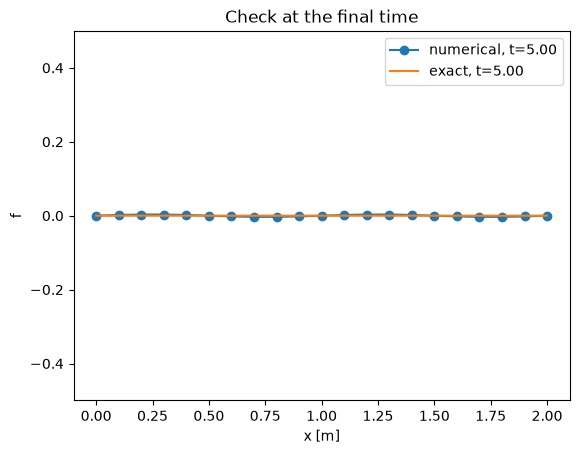

In [11]:
x_grid = np.linspace(0, L, n_points)

plt.plot(x_grid, result["f_history"][0], "o-", label="numerical, t=0")
plt.plot(x, analytical_solution(x, 0, A, k, D, u), label="exact, t=0")
plt.xlabel("x [m]")
plt.ylabel("f")
plt.legend()
plt.title("Check at t = 0")
plt.show()

t_check = result["t_history"][-1]
plt.plot(x_grid, result["f_history"][-1], "o-", label=f"numerical, t={t_check:.2f}")
plt.plot(x, analytical_solution(x, t_check, A, k, D, u), label=f"exact, t={t_check:.2f}")
plt.xlabel("x [m]")
plt.ylabel("f")
plt.legend()
plt.title("Check at the final time")
plt.ylim(-0.5, 0.5)
plt.show()

If the two curves overlap closely, the scheme behaves as expected. A clear mismatch indicates an error, to be resolved before Part 3.

## 3. Comparing the two solutions

### 3.1 Error between numerical and exact

The difference between the two curves at the final time is measured with:

In [12]:
a_final = analytical_solution(x_grid, t_check, A, k, D, u)  # exact solution at the same grid points and time
f_final = result["f_history"][-1]    # numerical solution at the final time

E = h * np.sqrt(np.sum((f_final - a_final)**2))   # L2 norm of the pointwise difference (Euclidean magnitude of the error values)
print(f"error at t = {t_check:.2f}: E = {E:.6e}")

error at t = 5.00: E = 1.037993e-03


### 3.2 Courant and diffusion numbers

The explicit scheme from Part 2 is only stable if the Courant number $Co$ and the diffusion number $Di$ satisfy:

$$
Co = \frac{u\Delta t}{h} < 1 \qquad\qquad Di = \frac{\Gamma\Delta t}{h^2} < \frac{1}{2}
$$

In [13]:
Co = u * dt / h
Di = D * dt / h**2
dt_max = min(h / u, 0.5 * h**2 / D) #maximum time step before one of the condition is not satisfied anymore
print(f"Co = {Co:.3f}, Di = {Di:.3f}, dt = {dt}, dt_max = {dt_max:.4f}")

Co = 0.500, Di = 0.250, dt = 0.05, dt_max = 0.1000


The behavior on both sides of this limit is examined next. The same scheme is run with three different time steps, safely below `dt_max`, close to it, and above it, and the final solution for each case is plotted on one figure:

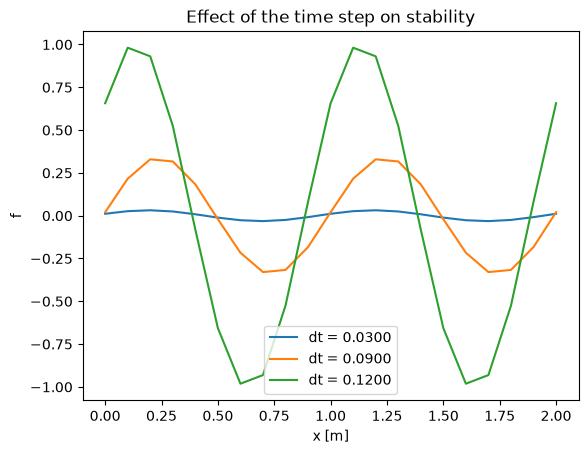

In [14]:
dt_values = [0.3 * dt_max, 0.9 * dt_max, 1.2 * dt_max]

plt.figure()
for dt_try in dt_values:
    nstep_try = int(2.0 / dt_try)
    result_try = run_numerical_scheme(n_points, nstep_try, L, dt_try, u, D, A, k) #our function previously implemented
    plt.plot(x_grid, result_try["f_history"][-1], label=f"dt = {dt_try:.4f}")

plt.xlabel("x [m]")
plt.ylabel("f")
plt.legend()
plt.title("Effect of the time step on stability")
plt.show()

Below `dt_max`, the curve remains smooth. Above it, small errors grow with every step instead of decaying, and the solution turns into noise unrelated to the underlying physics.

### 3.3 The Peclet number

The Peclet number compares advection to diffusion. At the scale of the whole domain:

$$
Pe = \frac{uL}{\Gamma}
$$

A large $Pe$ means advection dominates and the wave mostly travels. A small $Pe$ means diffusion dominates and the wave mostly spreads out and flattens.

There is a second, more local, Peclet number, built with the grid spacing $h$ instead of $L$:

$$
Pe_h = \frac{uh}{\Gamma}
$$

This one matters for the numerical scheme itself. With centered differences, a cell Peclet number above about 2 tends to produce wiggles in the solution that are not physical, on top of whatever the Courant and diffusion numbers already indicate about stability.

In [16]:
Pe = u * L / D
Pe_h = u * h*0.5 / D
print(f"global Peclet number: Pe = {Pe:.1f}")
print(f"cell Peclet number:   Pe_h = {Pe_h:.2f}")

global Peclet number: Pe = 40.0
cell Peclet number:   Pe_h = 1.00


With the default parameters, Pe>>1 so the flow is clearly advection dominated at the scale of the whole domain, since `Pe` is large. The cell Peclet number is much smaller, since it only compares advection and diffusion over one grid cell rather than the whole domain.

With `n_points`/2, how does `Pe_h` change? 

A coarser grid raises the cell Peclet number, even though nothing about the physics has changed.

### 3.4 Optimization

Refining the time step always reduces the temporal error, but increases computational cost, since more steps are needed to reach the same final time. This trade-off is examined directly: for a fixed grid, the scheme is run at many time steps between a small fraction of `dt_max` and just below it, recording both the final error and the number of steps needed.

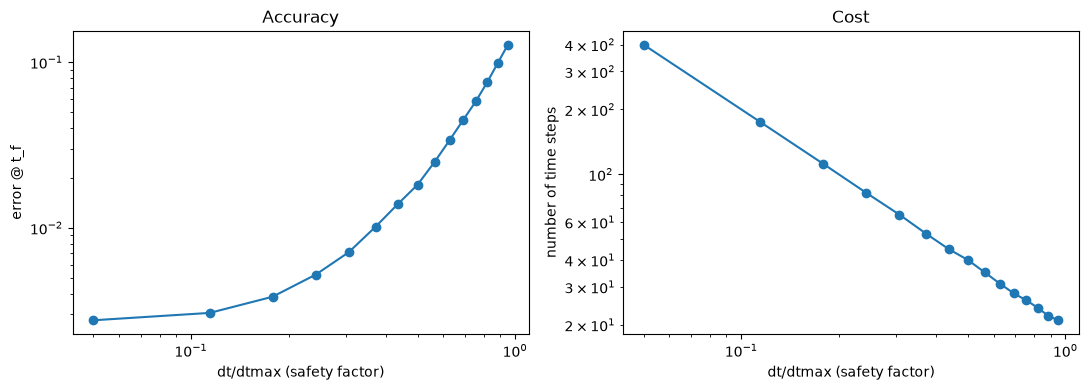

In [18]:
safety_factors = np.linspace(0.05, 0.95, 15) #all our dt

errors = []
n_steps_list = []

for sigma in safety_factors:
    dt_try = sigma * dt_max # trying dt in between 5% and 95& of the stability limit
    nstep_try = int(2.0 / dt_try)
    result_try = run_numerical_scheme(n_points, nstep_try, L, dt_try, u, D, A, k)

    t_final = result_try["t_history"][-1]
    a_try = analytical_solution(x_grid, t_final, A, k, D, u)
    f_try = result_try["f_history"][-1]
    E_try = h * np.sqrt(np.sum((f_try - a_try)**2))

    errors.append(E_try)
    n_steps_list.append(nstep_try)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.loglog(safety_factors, errors, "o-")
ax1.set_xlabel("dt/dtmax (safety factor)")
ax1.set_ylabel("error @ t_f")
ax1.set_title("Accuracy")

ax2.loglog(safety_factors, n_steps_list, "o-")
ax2.set_xlabel("dt/dtmax (safety factor)")
ax2.set_ylabel("number of time steps")
ax2.set_title("Cost")

plt.tight_layout()
plt.show()

The two plots are read together. Near a safety factor of 1, the error rises quickly, since the stability limit is being approached. Near a safety factor of 0, the error flattens out, since the time step is no longer the dominant source of error, while the number of steps keeps growing, so computational cost increases with little gain in accuracy. A suitable time step lies in between: small enough to remain clear of instability, large enough to avoid wasting computation. This is a first, simple example of a trade-off between accuracy and cost that recurs throughout computational fluid dynamics.

## Exercises

1. In Part 1, change `k` and `D` and describe how the wave shape and decay change.
2. In Part 2, push `dt` above `dt_max` on purpose and describe what the solution looks like after a few steps.
3. In Part 3, compute the cell Peclet number for `n_points = 11`, `21`, `41`, and `81`. Determine how many grid points are needed to bring `Pe_h` below 2.
4. Using the safety factor sweep in Section 3.4, select a safety factor suitable for practical use, and justify the choice in one or two sentences.
5. Implement a FDS and a BDS for our case study and compare the results

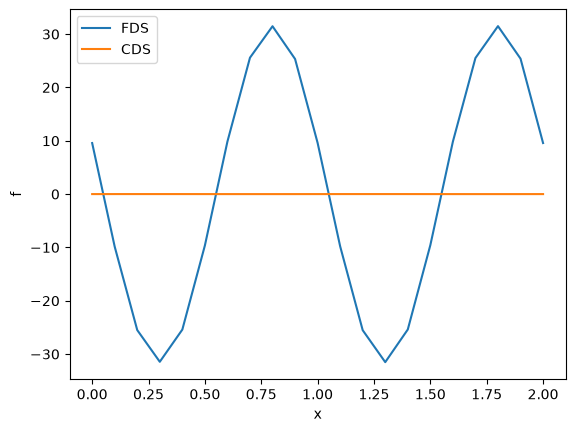

In [34]:
import numpy as np
import matplotlib.pyplot as plt


def run_numerical_scheme_fds(n_points, nstep, L, dt, u, D, A, k):
    h= L/(n_points-1)
    f = np.zeros(n_points)

    for i in range(n_points):
        f[i]=A*np.sin(2*3.14159*k*h*i)

    f_history = [f.copy()]
    t_history = [0.0]
    t = 0.0

    for m in range(nstep):
        f_old = f.copy()
        for i in range(1, n_points-1):
            f[i]= f_old[i] -(u*dt/h)*(f_old[i+1]-f_old[i]) +D*(dt/h**2)*(f_old[i+1]-2*f_old[i]+f_old[i-1])
        f[-1]=(f_old[-1])-(u*dt/h)*(f_old[1]-f[-1])+D*(dt/h**2)*(f_old[1]-2*f_old[-1]+f_old[-2])
        f[0]=f[-1]

        t=t+dt
        t_history.append(t)
        f_history.append(f.copy())

    return(f_history, t_history, h)

'''
L = 2.0   # domain length [m]
A = 0.5   # amplitude
k = 1     # wave number [1/m]
D = 0.05   # diffusion coefficient [m2/s] GAMMA
u = 1.0    # velocity [m/s]

n_points = 21   # number of grid points
nstep = 100     # number of time steps
dt = 0.05       # time step [s]
'''

result_fds= run_numerical_scheme_fds(21, 100, 2, 0.05, 1, 0.05, 0.5, 1)
result_cds= run_numerical_scheme(21, 100, 2, 0.05, 1, 0.05, 0.5, 1)
x_axis = np.linspace(0, 2.0, 21)

plt.plot(x_axis, result_fds[0][-1], label='FDS')
plt.plot(x_axis, result_cds["f_history"][-1], label='CDS')
plt.xlabel("x")
plt.ylabel("f")
plt.legend()
plt.show()



## Advection-diffusion-reaction equation in 1D

The previous parts covered advection and diffusion on their own. A reaction term is now added, and the explicit scheme is compared against an implicit one. The explicit Euler pattern is already familiar from the first part; the new piece here, worth building carefully, is the implicit scheme, which requires solving a linear system at every time step instead of a direct update.

### 4.1 Case description

The advection-diffusion-reaction equation in 1D, on a domain of length $L$:

$$
\frac{\partial C}{\partial t} + u \frac{\partial C}{\partial x} = \Gamma \frac{\partial^2 C}{\partial x^2} - kC
$$

with $C(x=0,\forall t) = C_{in}$ at the inlet and negligible diffusion at the outlet, and initial condition $C(t=0,\forall x) = C_0$.

**Explicit (forward) Euler**, centered 2nd order differences in space:

$$
\frac{C_i^{n+1} - C_i^n}{\Delta t} + u\,\frac{C_{i+1}^n - C_{i-1}^n}{2h} = \Gamma\,\frac{C_{i+1}^n - 2C_i^n + C_{i-1}^n}{h^2} - kC_i^n
$$

with the same stability limits on $Co$ and $Di$ as before.

**Implicit (backward) Euler**, same spatial discretization:

$$
\frac{C_i^n - C_i^{n-1}}{\Delta t} = -u\,\frac{C_{i+1}^n - C_{i-1}^n}{2h} + \Gamma\,\frac{C_{i+1}^n - 2C_i^n + C_{i-1}^n}{h^2} - kC_i^n
$$

Every $C^n$ term above is unknown, at every grid point at once, so this equation cannot be solved point by point, it has to be assembled into a linear system and solved in one shot.

**Boundary conditions**: a Dirichlet condition at the inlet, $C_1 = C_{in}$, and at the outlet, negligible diffusion reduces the equation to pure advection and reaction:

$$
\frac{\partial C}{\partial t} + u\frac{\partial C}{\partial x} = -kC
$$

### 4.2 Numerical setup

In [35]:
L = 1.0         # domain length [m]
n_points = 21   # number of grid points
nstep = 100     # number of time steps
dt = 0.025      # time step [s]
u = 0.5         # velocity [m/s]
D = 0.01        # diffusion coefficient [m2/s] GAMMA
kappa = 1.0     # kinetic constant [1/s]
C0 = 0.0        # initial concentration [kmol/m3]
Cin = 1.0       # inlet concentration [kmol/m3]

h = L / (n_points - 1)   # grid spacing

### 4.3 Explicit Euler

The interior update follows exactly the same pattern as Part 1's advection-diffusion scheme, with one addition: a reaction term. The reaction rate itself, $-kC_i^n$, is left out of the update below on purpose. Everything needed to add it is in the case description above.

In [36]:
def explicit_step(C_old, n_points, h, dt, u, D, kappa, Cin):
    '''One explicit Euler step. Returns the updated concentration array.'''
    C_new = np.zeros(n_points)
    C_new[0] = Cin   # inlet: Dirichlet condition

    for i in range(1, n_points - 1):
        dC_dx = (u / (2*h)) * (C_old[i+1] - C_old[i-1])  # u*∂C/∂x advection term
        d2C_dx2 = (D / h**2) * (C_old[i+1] - 2*C_old[i] + C_old[i-1]) # Γ*∂²C/∂x² diffusion term
        
        # the line below is missing the reaction contribution:
        C_new[i] = C_old[i] - dt*dC_dx + dt*d2C_dx2

    # outlet: negligible diffusion, advection and reaction only
    C_new[-1] = (C_old[-1] - (u*dt/h)*(C_old[-1] - C_old[-2])
                 - kappa*dt*C_old[-1])   # the outlet line already includes the reaction term, as a reference

    return C_new

Complete the interior update with the missing reaction term, then check the result: with `kappa = 0`, the outlet and the completed interior line should agree, since there is no reaction to tell them apart.

### 4.4 Implicit Euler

The implicit equation couples every grid point to its neighbors at the same, unknown time level. Collecting all the equations gives a linear system $A_{mat}\,C^n = b$, one row per grid point. The coefficients, constant here since nothing depends on time, are:

$$
A_P = 1 + \frac{2\Gamma\Delta t}{h^2} + k\Delta t \qquad
A_E = \frac{u\Delta t}{2h} - \frac{\Gamma\Delta t}{h^2} \qquad
A_W = -\frac{u\Delta t}{2h} - \frac{\Gamma\Delta t}{h^2}
$$

Row $i$ reads $A_W C_{i-1}^n + A_P C_i^n + A_E C_{i+1}^n = C_i^{n-1}$, for every interior point. The inlet row simply enforces $C_1^n = C_{in}$, and the outlet row enforces the reduced, diffusion-free equation from the case description.

In [37]:
AP = 1.0 + 2*D*dt/h**2 + kappa*dt
AE = u*dt/(2*h) - D*dt/h**2
AW = -u*dt/(2*h) - D*dt/h**2

Assembling `Amat` and `b` and solving the system is left as the main task of this practical. The inlet row, the interior rows, and the outlet row each need one or two lines. `numpy.linalg.solve(Amat, b)` is the direct equivalent of MATLAB's `Amat \ b`, and is what eventually turns `Amat` and `b` into the new `C_imp`.

### 4.5 Bringing it together

Both schemes are run side by side below, so they can be compared directly. The explicit step reuses the function from Section 4.3. The implicit step is where Section 4.5 needs to be completed: `Amat` and `b` are declared but never filled in, and the function stops with an error until that is done.

In [41]:
import numpy as np
def run_advection_diffusion_reaction(n_points, nstep, L, dt, u, D, kappa, C0, Cin, verbose=True):
    h = L / (n_points - 1)

    C_exp = np.zeros(n_points)
    C_imp = np.zeros(n_points)
    Amat = np.zeros((n_points, n_points)) #zeros matrix
    b = np.zeros(n_points)

    C_exp[0] = Cin
    C_imp[0] = Cin
    for i in range(1, n_points):
        C_exp[i] = C0
        C_imp[i] = C0

    AP = 1.0 + 2*D*dt/h**2 + kappa*dt
    AE = u*dt/(2*h) - D*dt/h**2
    AW = -u*dt/(2*h) - D*dt/h**2

    C_exp_history, C_imp_history, t_history = [], [], [] #empty lists

    t = 0.0
    for m in range(nstep):
        C_exp_history.append(C_exp.copy())
        C_imp_history.append(C_imp.copy())
        t_history.append(t)

        # explicit Euler, using the function from 4.3
        C_exp = explicit_step(C_exp, n_points, h, dt, u, D, kappa, Cin)

        # implicit Euler: 
        C_imp_old = C_imp.copy()

        # inlet row: Dirichlet condition, Amat[0, 0] and b[0]
        Amat[0,0]=1
        b[0]=Cin
        # interior rows, for i in range(1, n_points - 1): Amat[i, i-1], Amat[i, i], Amat[i, i+1], b[i]
        for i in range (1,n_points-1):
            Amat[i,i-1]=AW
            Amat[i,i]=AP
            Amat[i,i+1]=AE
            b[i]=C_imp_old[i]
        # outlet row: negligible diffusion, Amat[-1, -2] and Amat[-1, -1], b[-1]
        Amat[-1,-2]=-u*(dt/h)
        Amat[-1,-1]=1.0+u*(dt/h)+kappa*dt
        b[i]=C_imp_old[-1]

        C_imp=np.linalg.solve(Amat,b)
        
        t = t + dt
        if verbose and m % 25 == 0:
            print(f"time={t:.4f}")

    return {"C_exp_history": C_exp_history, "C_imp_history": C_imp_history,
            "t_history": t_history, "h": h}

result_reaction = run_advection_diffusion_reaction(
    n_points=n_points, nstep=nstep, L=L, dt=dt, u=u, D=D, kappa=kappa, C0=C0, Cin=Cin)

time=0.0250
time=0.6500
time=1.2750
time=1.9000


Running the cell above raises `NotImplementedError` until Section 4.4 is completed. Once `Amat`, `b`, and the call to `np.linalg.solve` are filled in, the error disappears and `result_reaction` holds the history of both schemes.

### 4.6 Graphical output

Once both schemes run, the two solutions can be animated together, exactly as in Part 1.

In [42]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

def animate_reaction(result, L, n_points):
    x_grid = np.linspace(0, L, n_points)

    fig, ax = plt.subplots(figsize=(7, 5))
    line_exp, = ax.plot([], [], linewidth=2, label="explicit")
    line_imp, = ax.plot([], [], linewidth=2, label="implicit")
    ax.set_xlim(0, L)
    ax.set_ylim(0, 1)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("concentration [kmol/m3]")
    ax.legend()
    title = ax.set_title("")

    def update(frame):
        line_exp.set_data(x_grid, result["C_exp_history"][frame])
        line_imp.set_data(x_grid, result["C_imp_history"][frame])
        title.set_text(f"t = {result['t_history'][frame]:.3f} s")
        return line_exp, line_imp, title

    anim = animation.FuncAnimation(fig, update, frames=len(result["C_exp_history"]),
                                    interval=60, blit=True)
    plt.close(fig)
    return anim

anim_reaction = animate_reaction(result_reaction, L, n_points)
HTML(anim_reaction.to_jshtml())

## 4. Exercises

1. Complete Section 6 and Section 7, then check that `C_exp_history` and `C_imp_history` agree closely at the final time, for the default parameters.
2. Push `Co` and `Di` above their stability limits and compare how the explicit and implicit schemes each react. Only one of them is expected to survive.
3. Replace the outlet boundary condition with a direct Neumann condition ($C_{n\_points-1} = C_{n\_points-2}$) and compare with the negligible-diffusion version used above.
4. Implement a dynamic inlet condition, $C(x=0) = C_{in}\left(1 + A\sin(2\pi ft)\right)$, and describe what changes in both schemes.
5. Implement a FDS and a BDS for the reaction case and compare the results.